# 02 - Preprocessing
**Goal:** turn the raw images of different sizes into clean arrays and create **one fixed train/test split** that *all ten models* will share.

| Step | Operation | Why |
|---|---|---|
| 1 | Show every operation on ONE image | understand what each step does |
| 2 | Load + resize all images to 64 x 64 | fixed input size |
| 3 | Grayscale version | HOG works on intensity/shape |
| 4 | Stratified 80 / 20 split | same class proportions in train and test |
| 5 | Save to `data/processed/dataset_64.npz` | notebooks 03-05 simply load it |

Pixel values are stored as `uint8` (0-255). Normalisation (/255) is done when a model needs it - this keeps the file small.

In [1]:
import sys; sys.path.append("..")          # lets the notebook import src/common.py
from src.common import *
import matplotlib.pyplot as plt, numpy as np, pandas as pd
print("Project root:", ROOT)
print("QUICK mode:", QUICK)
from PIL import Image
from skimage.color import rgb2gray
from sklearn.model_selection import train_test_split

Project root: C:\Users\ASUS\Desktop\image_classification_project
QUICK mode: False


## Step 1 - Every operation on one example image

saved -> results\figures\02_preprocessing_steps.png


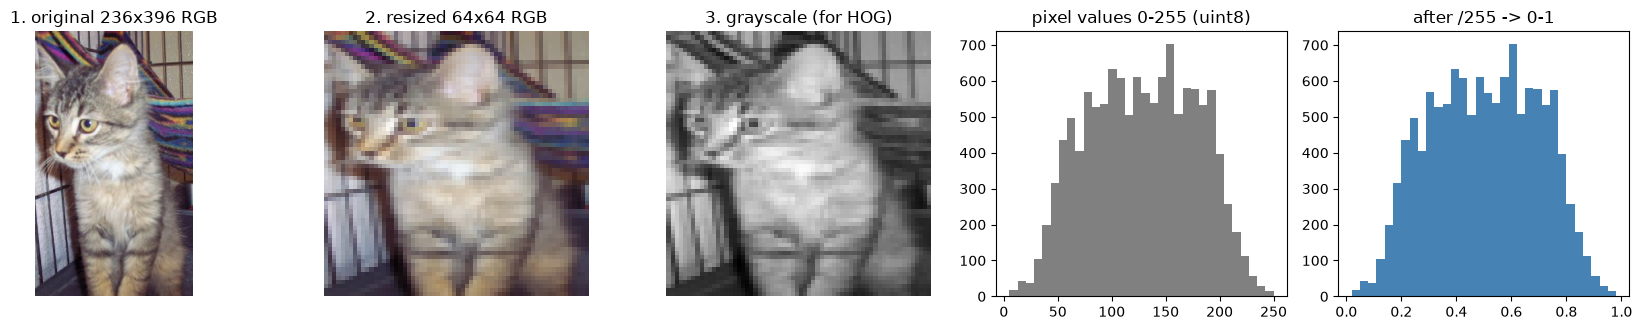

array shape: (64, 64, 3)  dtype: uint8  -> gray shape: (64, 64)


In [2]:
f = list_images("cat")[0]
raw = Image.open(f).convert("RGB")
resized = raw.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
arr_u8  = np.asarray(resized)                     # uint8, 0..255
arr_f   = arr_u8 / 255.0                          # float, 0..1   (normalisation)
gray    = rgb2gray(arr_f)                         # 64 x 64, one channel

fig, ax = plt.subplots(1, 5, figsize=(17, 3.4))
ax[0].imshow(raw);               ax[0].set_title(f"1. original {raw.size[0]}x{raw.size[1]} RGB")
ax[1].imshow(resized);           ax[1].set_title(f"2. resized {IMG_SIZE}x{IMG_SIZE} RGB")
ax[2].imshow(gray, cmap="gray"); ax[2].set_title("3. grayscale (for HOG)")
ax[3].hist(arr_u8.ravel(), bins=32, color="gray"); ax[3].set_title("pixel values 0-255 (uint8)")
ax[4].hist(arr_f.ravel(),  bins=32, color="steelblue"); ax[4].set_title("after /255 -> 0-1")
for a in ax[:3]: a.axis("off")
plt.tight_layout(); save_fig("02_preprocessing_steps.png"); plt.show()
print("array shape:", arr_u8.shape, " dtype:", arr_u8.dtype, " -> gray shape:", gray.shape)

## Step 2 - Load and resize the whole dataset

In [3]:
X, y = load_dataset()            # (N, 64, 64, 3) uint8 and (N,) labels
print("X:", X.shape, X.dtype, f"-> {X.nbytes/1e6:.0f} MB")
print("y:", y.shape, "classes:", np.bincount(y))

X: (6899, 64, 64, 3) uint8 -> 85 MB
y: (6899,) classes: [ 727  968  885  702  843 1000  788  986]


saved -> results\figures\02_resized_samples.png


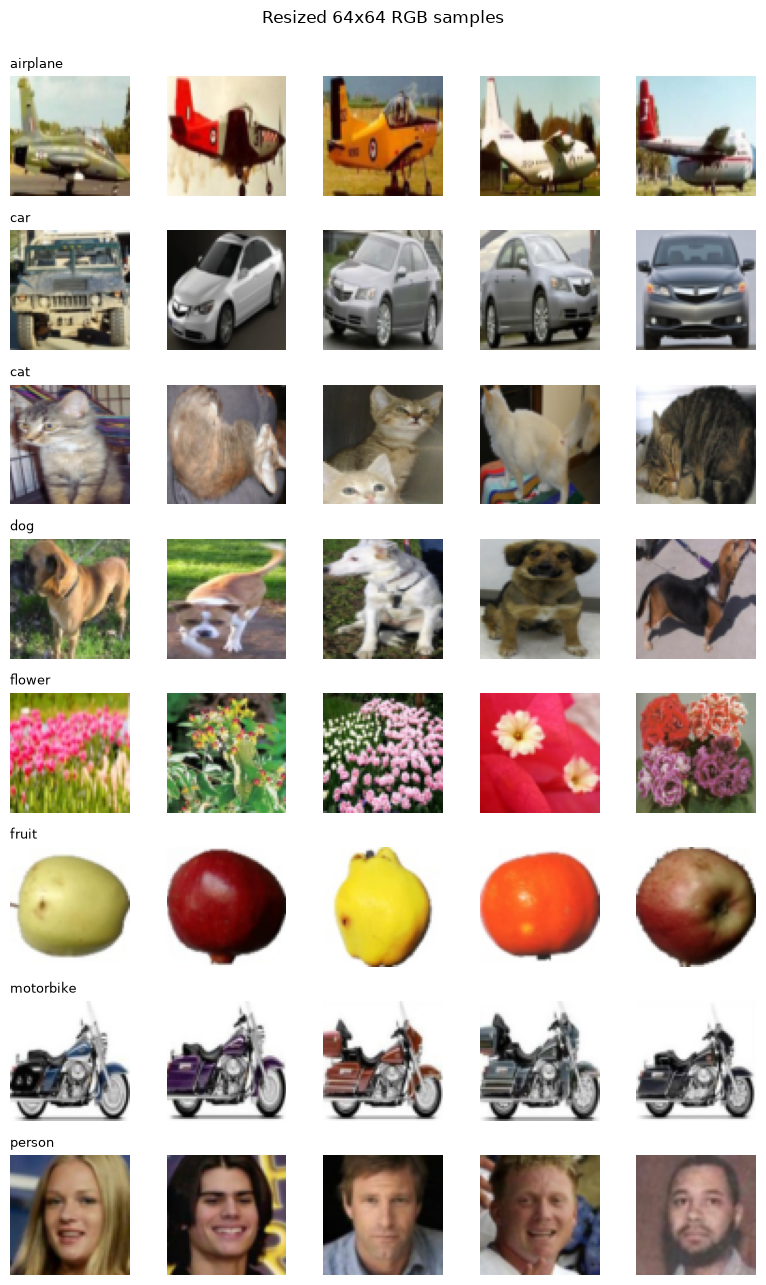

In [4]:
show_samples(X, y, 5, "Resized 64x64 RGB samples", "02_resized_samples.png")

## Step 3 - Grayscale preview (this is what HOG will "see")

saved -> results\figures\02_gray_samples.png


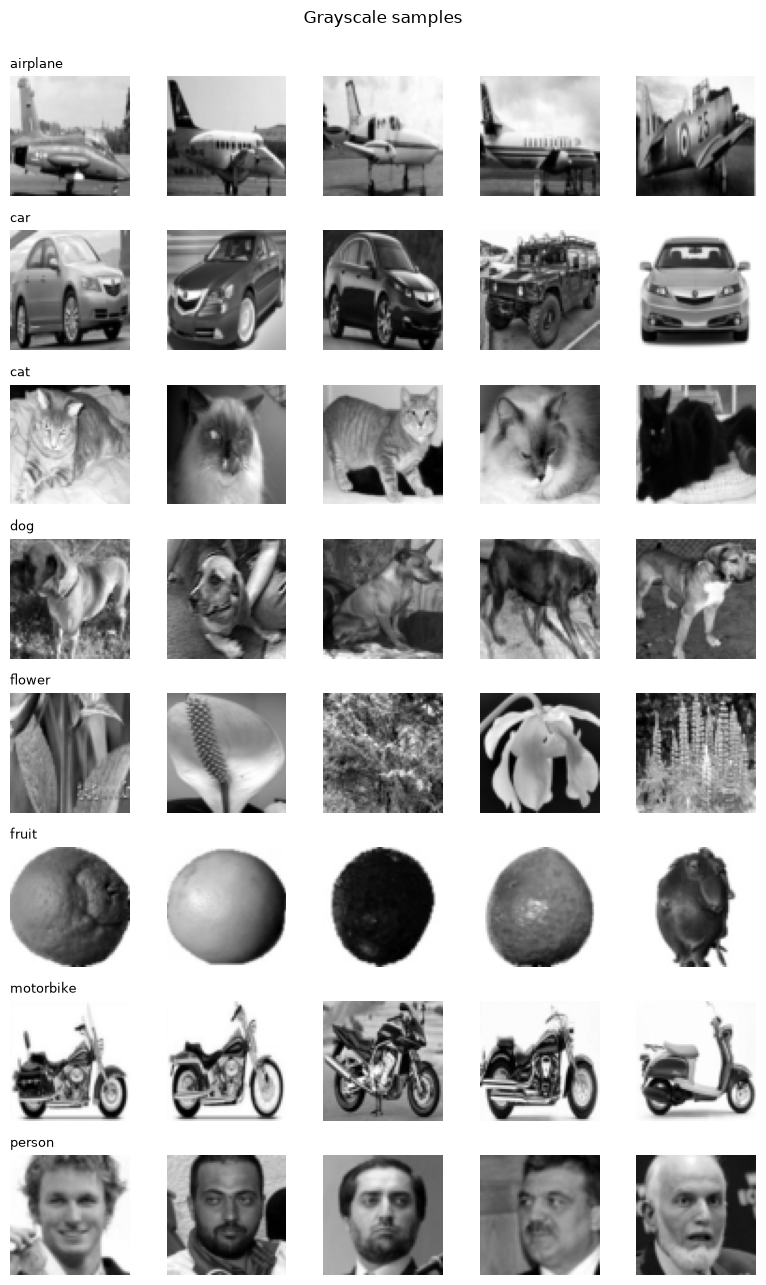

In [5]:
Xg_preview = np.stack([rgb2gray(img / 255.0) for img in X[::10]])
yg_preview = y[::10]
show_samples(Xg_preview, yg_preview, 5, "Grayscale samples", "02_gray_samples.png")

## Step 4 - Stratified train/test split
`stratify=y` keeps the same class proportions in both parts; `random_state` makes the split reproducible.
Because **every notebook loads this same file**, the ten models are compared on exactly the same test images.

train: (5519, 64, 64, 3)  test: (1380, 64, 64, 3)
saved -> results\figures\02_train_test_split.png


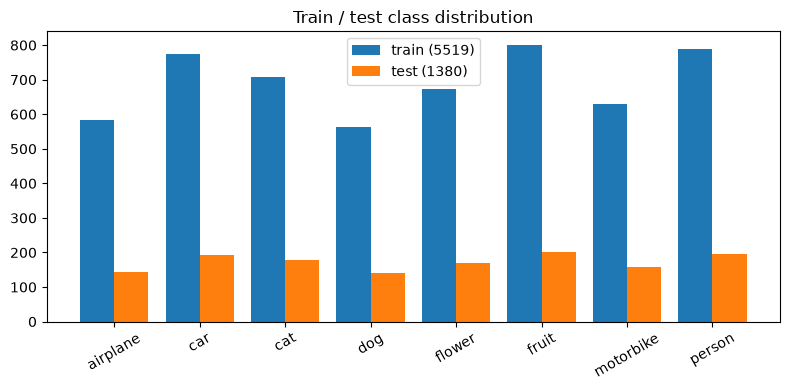

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

tr = np.bincount(y_train, minlength=len(CLASSES)); te = np.bincount(y_test, minlength=len(CLASSES))
fig, ax = plt.subplots(figsize=(8, 4)); w = 0.4; xs = np.arange(len(CLASSES))
ax.bar(xs - w/2, tr, w, label=f"train ({len(y_train)})"); ax.bar(xs + w/2, te, w, label=f"test ({len(y_test)})")
ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=30); ax.legend(); ax.set_title("Train / test class distribution")
plt.tight_layout(); save_fig("02_train_test_split.png"); plt.show()

## Step 5 - Save

In [7]:
np.savez_compressed(PROC_DIR / "dataset_64.npz",
                    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)
d = np.load(PROC_DIR / "dataset_64.npz")
print({k: d[k].shape for k in d.files})
print("saved ->", (PROC_DIR / "dataset_64.npz").relative_to(ROOT))

{'X_train': (5519, 64, 64, 3), 'X_test': (1380, 64, 64, 3), 'y_train': (5519,), 'y_test': (1380,)}
saved -> data\processed\dataset_64.npz


## Next
`03_hog_traditional_ml.ipynb` converts these images to HOG features and trains the six traditional models.